# Задание. Стихи в стиле Пушкина на n-граммной модели

**Тема:** статистические модели языка (лекция 1). **Данные:** собрание стихотворных текстов А. С. Пушкина, файл `data/pushkin.txt` (23 тысячи строк).

## Цель

Построить n-граммную языковую модель по стихам и научить её порождать новые строки. Модель не знает ни грамматики, ни размера, ни рифмы. Она только считает, какие слова идут друг за другом. Задание показывает, как много и как мало даёт такой подсчёт.

## План

| Часть | Содержание |
|---|---|
| 1 | Корпус и токенизация: слова, знаки препинания, конец строки |
| 2 | N-граммная модель: счётчики и вероятность следующего слова |
| 3 | Порождение текста: выборка, температура |
| 4 | Качество: перплексия и сглаживание |
| 5 | Задания для самостоятельного решения |

Части 1–4 разобраны полностью, их достаточно выполнить и прочитать. В части 5 семь заданий с самопроверкой.

## Обозначения

- $w_1,\dots,w_T$ обозначает последовательность токенов текста.
- $C(\cdot)$ обозначает число вхождений последовательности токенов в обучающий корпус.
- $n$ обозначает порядок модели: следующий токен предсказывается по $n-1$ предыдущим.
- $|V|$ обозначает размер словаря.

N-граммная модель оценивает вероятность следующего токена по частотам:

$$P(w_t\mid w_{t-n+1},\dots,w_{t-1})=\frac{C(w_{t-n+1},\dots,w_{t-1},w_t)}{C(w_{t-n+1},\dots,w_{t-1})}.$$

In [1]:
import math
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})

## Часть 1. Корпус и токенизация

Файл ищется в папке `data` в корне репозитория. Текст делится на строки, строка делится на токены трёх видов.

- **Слово** в нижнем регистре.
- **Знак препинания**: запятая, точка, тире и другие. Знаки оставлены, потому что они задают ритм строки.
- **Конец строки** `<nl>`. Благодаря этому токену модель сама решает, где закончить строку, и порождённый текст делится на строки стихотворения.

Последние 10 % строк откладываются для оценки качества и в обучении не участвуют.

In [2]:
def find_data(name):
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / "data" / name).exists():
            return parent / "data" / name
    raise FileNotFoundError(f"Файл data/{name} не найден в репозитории")


TOKEN_RE = re.compile(r"[а-яё]+(?:-[а-яё]+)*|[,.!?;:—]")
WORD_RE = re.compile(r"[а-яё]")
NL = "<nl>"

raw_lines = [l.strip() for l in open(find_data("pushkin.txt"), encoding="utf-8").read().split("\n")]
raw_lines = [l for l in raw_lines if WORD_RE.search(l.lower())]      # строки без слов (разделители, номера) отброшены
print("Строк в корпусе:", len(raw_lines))
print("\n".join(raw_lines[1000:1006]))


def tokenize(line):
    return TOKEN_RE.findall(line.lower().replace("–", "—")) + [NL]


n_train = int(0.9 * len(raw_lines))
train_tokens = [t for l in raw_lines[:n_train] for t in tokenize(l)]
test_tokens = [t for l in raw_lines[n_train:] for t in tokenize(l)]
vocab = sorted(set(train_tokens))
print(f"\nТокенов: обучение {len(train_tokens)}, отложенная часть {len(test_tokens)}. Размер словаря {len(vocab)}")
print("Пример:", tokenize(raw_lines[1000]))

Строк в корпусе: 23132
Да приплода поджидать.
Ветер по морю гуляет
И кораблик подгоняет;
Он бежит себе в волнах
На раздутых парусах
Мимо острова крутого,

Токенов: обучение 138904, отложенная часть 16414. Размер словаря 23203
Пример: ['да', 'приплода', 'поджидать', '.', '<nl>']


## Часть 2. N-граммная модель

Модель хранит таблицу счётчиков: для каждого контекста из $n-1$ токенов записано, какие токены шли после него и сколько раз. Обучение сводится к одному проходу по корпусу.

Если контекст в корпусе не встречался, вероятность по формуле не определена. Модель в таком случае отступает к более короткому контексту: вместо двух предыдущих слов берёт одно, затем ни одного. Этот приём называется откатом (backoff).

In [3]:
class NGramModel:
    # N-граммная модель с откатом к более короткому контексту.

    def __init__(self, n):
        self.n = n
        self.counts = [defaultdict(Counter) for _ in range(n)]      # counts[k][контекст длины k][токен]

    def fit(self, tokens):
        padded = [NL] * (self.n - 1) + tokens
        for i in range(self.n - 1, len(padded)):
            for k in range(self.n):                                 # все порядки от 1 до n
                self.counts[k][tuple(padded[i - k:i])][padded[i]] += 1
        self.vocab_size = len(self.counts[0][()])
        # суммы счётчиков по каждому контексту считаются один раз
        self.totals = [{ctx: sum(c.values()) for ctx, c in level.items()} for level in self.counts]
        return self

    def distribution(self, context):
        # Счётчики продолжений для самого длинного контекста, который встречался в корпусе.
        context = tuple(context)[-(self.n - 1):] if self.n > 1 else ()
        while context not in self.counts[len(context)]:
            context = context[1:]
        return self.counts[len(context)][context]

    def prob(self, token, context, k=0.0):
        # Вероятность токена после контекста; k > 0 включает аддитивное сглаживание.
        context = tuple(context)[-(self.n - 1):] if self.n > 1 else ()
        c = self.counts[len(context)].get(context)
        total = self.totals[len(context)].get(context, 0)
        if total + k * self.vocab_size == 0:
            return 0.0
        return ((c[token] if c else 0) + k) / (total + k * self.vocab_size)


bigram = NGramModel(2).fit(train_tokens)
trigram = NGramModel(3).fit(train_tokens)

print("После слова «буря» чаще всего идут:", trigram.counts[1][("буря",)].most_common(6))
print("После слов «я помню» идут:", trigram.counts[2][("я", "помню")].most_common(6))
c = bigram.counts[1][("буря",)]
print(f"P(мглою | буря) = {c['мглою']} / {bigram.totals[1][('буря',)]} = {bigram.prob('мглою', ['буря']):.3f}")

После слова «буря» чаще всего идут: [(',', 2), ('<nl>', 2), ('мглою', 2), (':', 1), ('подымалась', 1), ('мрачная', 1)]
После слов «я помню» идут: [('их', 1), ('моленья', 1), ('твой', 1), ('скал', 1), ('вод', 1), ('чудное', 1)]
P(мглою | буря) = 2 / 13 = 0.154


**Что видно.** Для каждого контекста модель знает распределение следующих токенов. Чем длиннее контекст, тем меньше у него разных продолжений и тем точнее предсказание. Вместе с тем длинный контекст встречается в корпусе реже, и оценка по нескольким примерам ненадёжна. Это и есть разреженность данных из лекции 1.

Рисунок показывает, сколько разных контекстов длины 1, 2 и 3 есть в корпусе и какая их доля встретилась ровно один раз.

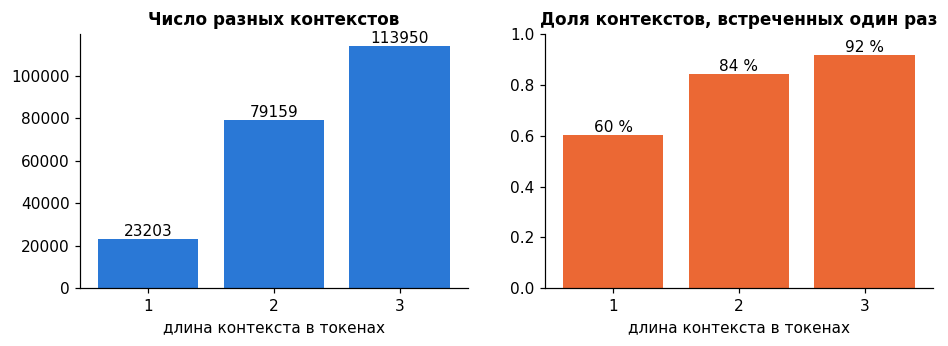

In [4]:
m4 = NGramModel(4).fit(train_tokens)
ks = [1, 2, 3]
n_ctx = [len(m4.counts[k]) for k in ks]
once = [sum(1 for v in m4.totals[k].values() if v == 1) / len(m4.totals[k]) for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar([str(k) for k in ks], n_ctx, color=BLUE)
for i, v in enumerate(n_ctx):
    axes[0].text(i, v, f"{v}", ha="center", va="bottom")
axes[0].set_title("Число разных контекстов"); axes[0].set_xlabel("длина контекста в токенах")
axes[1].bar([str(k) for k in ks], once, color=ORANGE)
for i, v in enumerate(once):
    axes[1].text(i, v, f"{100 * v:.0f} %", ha="center", va="bottom")
axes[1].set_title("Доля контекстов, встреченных один раз"); axes[1].set_xlabel("длина контекста в токенах"); axes[1].set_ylim(0, 1)
plt.show()

## Часть 3. Порождение текста

Текст порождается по одному токену. Модель берёт распределение продолжений для текущего контекста, случайно выбирает из него токен и добавляет его к тексту. Выбранный токен входит в контекст следующего шага.

**Температура** $T$ меняет распределение перед выборкой: вероятности возводятся в степень $1/T$ и заново нормируются. При $T<1$ частые продолжения становятся ещё вероятнее, текст получается предсказуемым. При $T>1$ распределение выравнивается, текст получается разнообразным и менее связным.

In [5]:
_sample_cache = {}


def sample_token(counter, temperature, rng):
    key = (id(counter), temperature)
    if key not in _sample_cache:                              # для больших распределений веса считаются один раз
        tokens = list(counter)
        weights = np.array([counter[t] for t in tokens], dtype=float) ** (1.0 / temperature)
        _sample_cache[key] = (tokens, np.cumsum(weights / weights.sum()))
    tokens, cdf = _sample_cache[key]
    return tokens[min(int(np.searchsorted(cdf, rng.random_sample())), len(tokens) - 1)]


def generate(model, n_lines=4, start=None, temperature=1.0, seed=SEED, max_tokens=400):
    # Порождает n_lines строк. start задаёт начало первой строки.
    rng = np.random.RandomState(seed)
    out = tokenize(start)[:-1] if start else []
    context = [NL] + out                                        # текст начинается с начала строки
    lines_done, skipped = 0, 0
    while lines_done < n_lines and len(out) < max_tokens:
        tok = sample_token(model.distribution(context), temperature, rng)
        if tok == NL and (not out or out[-1] in (NL, ",", ";", ":", "—")) and skipped < 20:
            skipped += 1                                        # строка не должна быть пустой
            continue
        skipped = 0
        out.append(tok); context.append(tok)
        lines_done += tok == NL
    return out


def detokenize(tokens):
    lines, cur = [], []
    for t in tokens:
        if t == NL:
            lines.append(cur); cur = []
        else:
            cur.append(t)
    if cur:
        lines.append(cur)
    text = []
    for words in lines:
        s = ""
        for w in words:
            s += w if (w in ",.!?;:" or not s) else " " + w
        text.append(s[:1].upper() + s[1:])
    return "\n".join(text)


for n, model in [(1, NGramModel(1).fit(train_tokens)), (2, bigram), (3, trigram), (4, m4)]:
    print(f"--- порядок модели n = {n} ---")
    print(detokenize(generate(model, n_lines=4, seed=7)))
    print()

--- порядок модели n = 1 ---
, любят ни легко свободна царь со,. между меньшие злата за, не светлых
Сердце ослепляя, снова оливу
Она посмеешься
Я туманом горы —! и вас и умножить миг в будешь. верный и плод и моря вспомнил; цирцей

--- порядок модели n = 2 ---
Не правда, нет соперниц, спору нет, добычи ищут, завиден гордый ум он: жду красавицу венчай
Душа желанья
Из дома, вакх и хладны.
Корабельщики в поздний вижу то наша дева росла, дрожащий, мой гонитель

--- порядок модели n = 3 ---
Не переводчикам голодным,
И глухо тополы шумят —
В одежде белой над волнами
Плыл качаясь, как сон пустой,

--- порядок модели n = 4 ---
Не переводчикам голодным,
Не требуй от меня стихов.
Не спрашивай, за чем унылой думой
Среди забав я часто омрачен,



**Что видно.** Униграммная модель выбирает слова независимо и выдаёт бессвязный набор. Биграммная согласует соседние слова. Триграммная порождает осмысленные сочетания и сама расставляет концы строк. Модель четвёртого порядка звучит лучше всех, и здесь есть подвох: она воспроизводит строки Пушкина дословно. Длинный контекст встречался в корпусе один раз и имел единственное продолжение, поэтому модель идёт по обучающему тексту как по рельсам. В задании 4 это измеряется.

Порождение можно начать с заданных слов.

In [6]:
for T in (0.5, 1.0, 1.5):
    print(f"--- температура T = {T} ---")
    print(detokenize(generate(trigram, n_lines=4, start="Я помню", temperature=T, seed=3)))
    print()

--- температура T = 0.5 ---
Я помню скал прибрежные стремнины,
И в хрустальном гробе том
Спит увенчанный счастливец;
В поместье мирное меж пиндом и цитерой,

--- температура T = 1.0 ---
Я помню скал прибрежные стремнины,
Моей мучительной любви.
Зову тебя не для них — весенни розы, девы красоты;
Восстал вселенной бич — и гладкая гора,

--- температура T = 1.5 ---
Я помню скал прибрежные стремнины,
Издавна мудрые искали
Забытых истины следов
Коснуться жаркими устами,



## Часть 4. Качество: перплексия и сглаживание

Перплексия измеряет, насколько хорошо модель предсказывает отложенный текст:

$$\mathrm{PPL}=\exp\Big(-\frac{1}{T}\sum_{t=1}^{T}\ln P(w_t\mid\text{контекст})\Big).$$

Чем меньше перплексия, тем лучше. Если хотя бы один токен отложенного текста получает нулевую вероятность, логарифм не определён и перплексия бесконечна. Для оценки по частотам это случается постоянно: в отложенных строках есть сочетания, которых не было в обучении.

Аддитивное сглаживание прибавляет к каждому счётчику число $k$:

$$P(w\mid h)=\frac{C(h,w)+k}{C(h)+k\,|V|},$$

где $h$ обозначает контекст. При $k=1$ это сглаживание Лапласа. Слова отложенной части, которых нет в словаре, при подсчёте пропускаются.

Без сглаживания (k = 0): биграммная модель inf


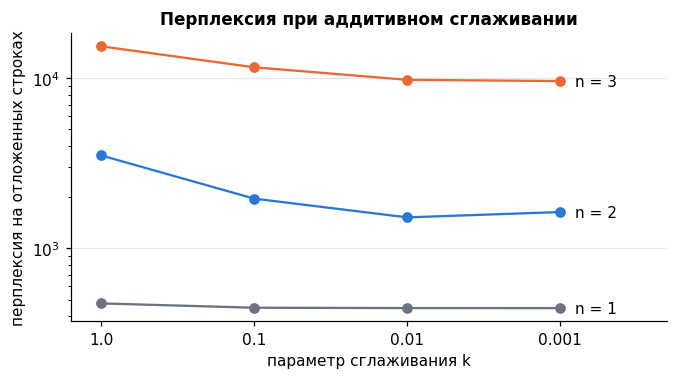

n = 1: {1.0: 475, 0.1: 448, 0.01: 446, 0.001: 446}
n = 2: {1.0: 3520, 0.1: 1961, 0.01: 1522, 0.001: 1635}
n = 3: {1.0: 15409, 0.1: 11601, 0.01: 9792, 0.001: 9627}


In [7]:
def perplexity(model, tokens, k):
    vocab_set = set(model.counts[0][()])
    padded = [NL] * (model.n - 1) + tokens
    log_sum, count = 0.0, 0
    for i in range(model.n - 1, len(padded)):
        tok = padded[i]
        if tok not in vocab_set:
            continue
        p = model.prob(tok, padded[i - model.n + 1:i], k=k)
        if p == 0:
            return float("inf")
        log_sum += math.log(p); count += 1
    return math.exp(-log_sum / count)


unigram = NGramModel(1).fit(train_tokens)
k_grid = [1.0, 0.1, 0.01, 0.001]
ppl = {n: [perplexity(m, test_tokens, k) for k in k_grid] for n, m in [(1, unigram), (2, bigram), (3, trigram)]}
print("Без сглаживания (k = 0): биграммная модель", perplexity(bigram, test_tokens, 0.0))

fig, ax = plt.subplots(figsize=(7, 3.4))
for n, col in [(1, MUTED), (2, BLUE), (3, ORANGE)]:
    ax.plot(range(len(k_grid)), ppl[n], marker="o", color=col)
    ax.text(len(k_grid) - 0.9, ppl[n][-1], f"n = {n}", va="center")
ax.set_xticks(range(len(k_grid))); ax.set_xticklabels(k_grid); ax.set_xlim(-0.2, len(k_grid) - 0.3)
ax.set_yscale("log"); ax.set_xlabel("параметр сглаживания k"); ax.set_ylabel("перплексия на отложенных строках")
ax.set_title("Перплексия при аддитивном сглаживании"); ax.grid(axis="y", color=GRID)
plt.show()
for n in ppl:
    print(f"n = {n}:", {k: round(v) for k, v in zip(k_grid, ppl[n])})

**Что видно на рисунке.** Без сглаживания перплексия бесконечна. Со сглаживанием при любом $k$ лучшей оказывается униграммная модель, биграммная хуже неё в несколько раз, триграммная ещё хуже. Причина в размере корпуса: словарь содержит более 20 тысяч слов, а большинство пар и троек слов из отложенных строк в обучении не встречалось. Аддитивное сглаживание раздаёт вероятность всем невиданным продолжениям поровну и с такой разреженностью не справляется. Для длинных контекстов нужны более тонкие методы: откат и интерполяция.

Вывод для порождения: модель высокого порядка звучит связнее, хотя новый текст предсказывает хуже. Связность она получает ценой повторения обучающих строк.

## Часть 5. Задания для самостоятельного решения

Замените многоточия своим кодом. После каждого задания запишите вывод в одну-две фразы в отдельной ячейке. В заданиях используются объекты из частей 1–4: `raw_lines`, `train_tokens`, `test_tokens`, `tokenize`, `detokenize`, `NGramModel`, `generate`, `perplexity`, модели `unigram`, `bigram`, `trigram`, `m4`.

### Задание 1. Частоты слов и закон Ципфа

1. Найдите 15 самых частых слов корпуса (без знаков препинания и без `<nl>`).
2. Постройте график зависимости частоты слова от его ранга в логарифмических осях.
3. Найдите долю слов словаря, которые встретились в обучающей части ровно один раз.

**Самопроверка.** Самое частое слово «и». Доля слов, встретившихся один раз, лежит между 55 % и 65 %. График в логарифмических осях близок к прямой.

In [ ]:
words = [t for t in train_tokens if ...]
freq = Counter(words)
print(...)

# график ранг-частота
...

hapax_share = ...
print(hapax_share)

### Задание 2. Вероятность строки

Напишите функцию `line_logprob(model, line, k)`, которая возвращает логарифм вероятности строки по модели со сглаживанием $k$. Строка токенизируется функцией `tokenize`, контекст перед строкой состоит из токенов `<nl>`.

Сравните по биграммной модели при $k=0.01$ три строки: настоящую строку Пушкина «Мороз и солнце; день чудесный!», ту же строку с переставленными словами «Чудесный солнце день и мороз!» и строку современной прозы «Компьютер завис и не отвечает.»

**Самопроверка.** Логарифм вероятности настоящей строки наибольший, строки прозы наименьший. Разница между первой и третьей строкой больше 10.

In [ ]:
def line_logprob(model, line, k=0.01):
    tokens = tokenize(line)
    ...


for line in ["Мороз и солнце; день чудесный!", "Чудесный солнце день и мороз!", "Компьютер завис и не отвечает."]:
    print(round(line_logprob(bigram, line), 1), line)

### Задание 3. Температура

Породите триграммной моделью по 200 строк при температурах 0.3, 0.7, 1.0, 1.5 и 2.0 (один вызов `generate` с `n_lines=200` на каждую температуру). Для каждого текста посчитайте долю разных слов среди всех слов текста. Постройте график этой доли от температуры и выведите по четыре строки для самой низкой и самой высокой температуры.

**Самопроверка.** Доля разных слов растёт с температурой: при 0.3 она меньше 0.45, при 2.0 больше 0.60.

In [ ]:
temps = [0.3, 0.7, 1.0, 1.5, 2.0]
diversity = []
for T in temps:
    tokens = generate(trigram, n_lines=200, temperature=T, seed=1, max_tokens=5000)
    words = ...
    diversity.append(...)
print(diversity)
...

### Задание 4. Порядок модели и дословные заимствования

Модель высокого порядка может повторять обучающий текст. Измерьте это.

1. Соберите множество всех обучающих строк в виде кортежей токенов.
2. Для моделей порядка 2, 3, 4 и 5 породите по 300 строк и посчитайте долю порождённых строк, которые дословно совпадают с какой-либо обучающей строкой.
3. Постройте столбчатую диаграмму и выберите порядок модели для порождения стихов. Обоснуйте выбор.

**Самопроверка.** Доля дословных совпадений растёт с порядком модели: для $n=2$ она меньше 5 %, для $n=4$ и $n=5$ больше 80 %.

In [ ]:
train_lines = set(...)            # множество кортежей токенов обучающих строк


def copied_share(model, n_lines=300, seed=1):
    tokens = generate(model, n_lines=n_lines, seed=seed, max_tokens=10000)
    ...


for n in (2, 3, 4, 5):
    model = NGramModel(n).fit(train_tokens)
    print(n, copied_share(model))

### Задание 5. Подбор сглаживания

Параметр $k$ нельзя подбирать на тех же строках, на которых измеряется итоговое качество. Разделите отложенную часть пополам: первая половина служит проверочной, вторая тестовой.

1. Для биграммной модели найдите на проверочной половине лучшее значение $k$ из набора $\{1,\ 0.3,\ 0.1,\ 0.03,\ 0.01,\ 0.003,\ 0.001\}$.
2. Посчитайте перплексию на тестовой половине при найденном $k$ и при $k=1$.

**Самопроверка.** Лучшее значение $k$ лежит между 0.003 и 0.03. Перплексия на тестовой половине при лучшем $k$ меньше, чем при $k=1$, не менее чем в два раза.

In [ ]:
half = len(test_tokens) // 2
dev_tokens, final_tokens = test_tokens[:half], test_tokens[half:]
grid = [1, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001]
dev_ppl = ...
best_k = ...
print(best_k, ...)

### Задание 6. Рифма

N-граммная модель рифму не учитывает. Добавьте её отбором: порождайте пары строк и оставляйте только те, в которых последние слова рифмуются.

1. Напишите функцию `rhymes(a, b)`: два слова считаются рифмой, если они различны и у них совпадают три последние буквы.
2. Напишите функцию `couplet(model, seed)`: она порождает первую строку, затем порождает вторую строку до тех пор, пока её последнее слово не срифмуется с последним словом первой (не более 300 попыток). Функция возвращает две строки и число попыток.
3. Выведите пять двустиший триграммной модели и среднее число попыток.

**Самопроверка.** Рифма находится не для каждой первой строки. Среднее число попыток измеряется десятками и сотнями. Объясните, от чего зависит число попыток.

In [ ]:
def last_word(tokens):
    words = [t for t in tokens if re.fullmatch(r"[а-яё-]+", t)]
    return words[-1] if words else ""


def rhymes(a, b):
    ...


def couplet(model, seed, max_tries=300):
    ...


for s in range(5):
    print(couplet(trigram, s))

### Задание 7 (повышенной сложности). Четверостишие с перекрёстной рифмой

Породите четверостишие со схемой рифмовки ABAB: первая строка рифмуется с третьей, вторая с четвёртой. Используйте функции задания 6. Третья и четвёртая строки порождаются с учётом предыдущих строк как контекста, чтобы текст оставался связным.

Выведите три четверостишия. Оцените результат: что в нём похоже на стихи и чего не хватает? Какие свойства стиха n-граммная модель не может выучить в принципе и почему?

**Самопроверка.** Строки с номерами 1 и 3, 2 и 4 оканчиваются на рифмующиеся слова. В ответе названы хотя бы два свойства стиха, недоступные модели: размер и ударения, связь между далёкими строками, общий смысл.

In [ ]:
def quatrain(model, seed):
    ...


for s in range(3):
    print(quatrain(trigram, s), "\n")

## Что сдавать

Блокнот, который выполняется целиком без ошибок, с решениями заданий 1–6 и выводами к каждому заданию. Задание 7 выполняется по желанию.

- [ ] Отложенные строки не участвуют в обучении модели.
- [ ] Параметр сглаживания подобран на проверочной половине, итоговое качество измерено на тестовой.
- [ ] Значение `seed` зафиксировано, результат воспроизводится.
- [ ] К каждому заданию записан вывод со ссылкой на полученные числа.